In [1]:
%load_ext rpy2.ipython

/Users/arturohernanzcarrasco-munoz/code/analisis_datos_series_temporales/.venv/lib/python3.9/site-packages/rpy2/ipython/rmagic.py:96: UserWarning: The Python package `pandas` is strongly recommended when using `rpy2.ipython`. Unfortunately it could not be loaded, as we did not manage to load `numpy` in the first place (error: No module named 'numpy').
  warnings.warn('The Python package `pandas` is strongly '


In [2]:
%%R
lib_loc <- "lib_loc"

In [3]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [62]:
%%R
options (repos = c(CRAN = "https://cloud.r-project.org"))

if(!require("stats")) install.packages("stats")
library(stats, lib.loc=lib_loc)
if(!require("ggplot2")) install.packages("ggplot2")
library(ggplot2, lib.loc=lib_loc)
if(!require("ggfortify")) install.packages("ggfortify")
library(ggfortify, lib.loc=lib_loc)
if (!require("zoo", lib.loc = lib_loc)) install.packages("zoo", lib = lib_loc)
library(zoo, lib.loc = lib_loc)
if (!require("forecast", lib.loc = lib_loc)) install.packages("forecast", lib = lib_loc)
library(forecast, lib.loc = lib_loc)


Loading required package: forecast
Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 
Registered S3 methods overwritten by 'forecast':
  method                 from     
  autoplot.Arima         ggfortify
  autoplot.acf           ggfortify
  autoplot.ar            ggfortify
  autoplot.bats          ggfortify
  autoplot.decomposed.ts ggfortify
  autoplot.ets           ggfortify
  autoplot.forecast      ggfortify
  autoplot.stl           ggfortify
  autoplot.ts            ggfortify
  fitted.ar              ggfortify
  fortify.ts             ggfortify
  residuals.ar           ggfortify


# Carga del fichero

In [58]:
%%R

dfMedidas <- read.csv("AirPassengers.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)

dfMedidas$año <- substr(dfMedidas$Month, 1, 4)
dfMedidas$mes <- substr(dfMedidas$Month, 6, 7)



In [59]:
%%R
head(dfMedidas)

    Month #Passengers  año mes
1 1949-01         112 1949  01
2 1949-02         118 1949  02
3 1949-03         132 1949  03
4 1949-04         129 1949  04
5 1949-05         121 1949  05
6 1949-06         135 1949  06


# Visualizamos los datos:

Visualizamos todos los valores:

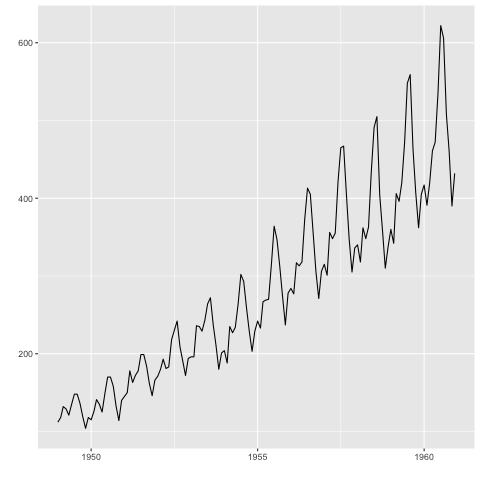

In [61]:
%%R
ts_TMED <- ts(dfMedidas$'#Passengers', frequency = 12, start = 1949) 
autoplot(ts_TMED)

Podemos ver que la distribución de los datos es ciclica cada año pero lineal en su conjunto, además, podemos ver que cada año aumenta el número de pasajeros.

# EDA:

## Distribución de los datos:

Usamos la libreria forecast para analizar las tendencias mensuales de cada año 

In addition: Warning message:
In fortify(data, ...) : Arguments in `...` must be used.
✖ Problematic argument:
• na.rm = TRUE
ℹ Did you misspell an argument name?


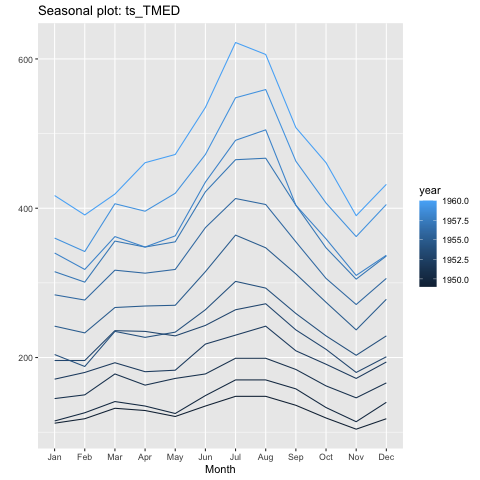

In [63]:
%%R
ggseasonplot(ts_TMED, continuous = TRUE)

In addition: Warning message:
In fortify(data, ...) : Arguments in `...` must be used.
✖ Problematic argument:
• na.rm = TRUE
ℹ Did you misspell an argument name?


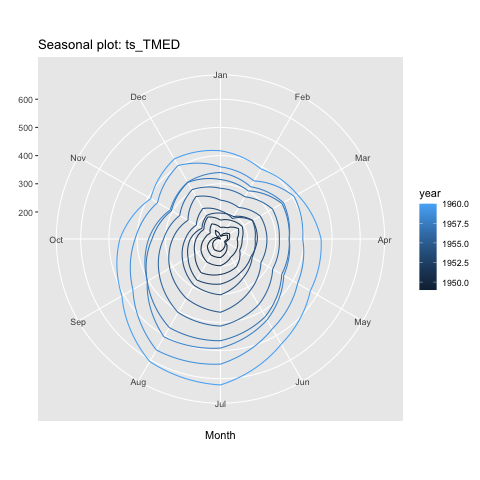

In [64]:
%%R
ggseasonplot(ts_TMED, continuous = TRUE, polar=TRUE)

In addition: Warning message:
In fortify(data, ...) : Arguments in `...` must be used.
✖ Problematic argument:
• na.rm = TRUE
ℹ Did you misspell an argument name?


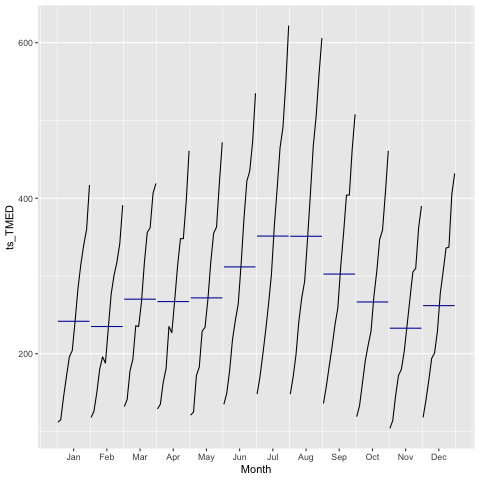

In [65]:
%%R
ggsubseriesplot(ts_TMED)

Las 2 primeras gráficas muestran el número de pasajeros por año con una línea de tonalidad azul (cuanto más antiguo es el año, más oscuro es el color), mientras que la última gráfica muestra la misma información pero centrandose en los meses y no en los años, es decir, agrupa el número de pasajeros de cada mes en una línea de tendencia vertical.

Como hemos visto anteriormente, cada año el número de pasajeros aumenta. 
Como novedad aportada por estas gráfica podemos ver las tendencias por mes:
Se puede comprobar un aumento del número de viajes en avión en los meses de verano (finales de mayo a septiembre), con el mayor número en los meses de julio y agosto.
Es curioso como estos picos se van alternando cada pocos años, cada 2/3 años julio y agosto se turnan el liderzgo de más viajeros por mes.

A la hora de discutir la frecuencia correcta de los datos, usamos la siguiente gráfica, que muestra la distribución de un dato en el instante t frente a otro en el instante t-lag(n). 

El punto de mayor correlación mostrará la frecuencia correcta.

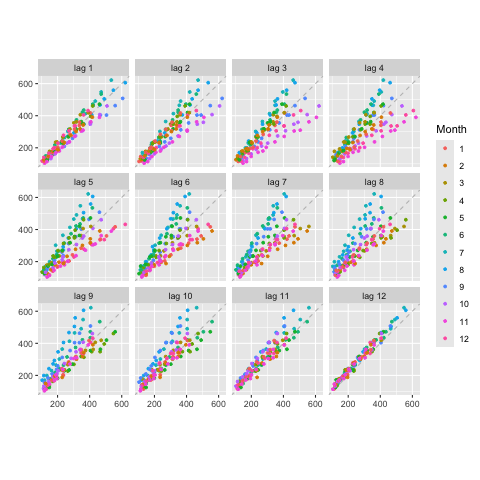

In [66]:
%%R
gglagplot(ts_TMED, do.lines = FALSE, lags = 12) + geom_point(size = 0.1, stroke = 0)

Efectivamente, la frecuencia es de 12 meses.

## Correlación de los datos:

Evaluamos la autocorrelación de la serie:

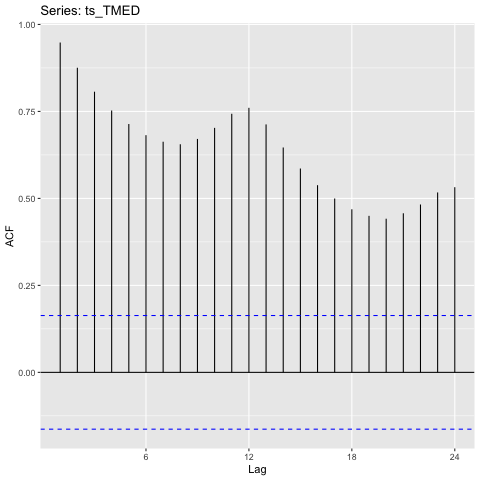

In [67]:
%%R
ggAcf(ts_TMED)

* Tendencia descendente --> Serie no estacionaria
* 

## Descomposición de la serie